In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression, BayesianRidge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [49]:
covid_df = pd.read_csv('covid_19_clean_complete.csv')
country_df = pd.read_csv('country_wise_latest.csv')
day_df = pd.read_csv('day_wise.csv')
world_df = pd.read_csv('worldometer_data.csv')

# Load CSV (make sure filename matches extracted file)
usa_df = pd.read_csv('usa_county_wise.csv')

usa_df.head()

covid_df
country_df
day_df
world_df

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region
0,USA,North America,3.311981e+08,5032179,NaN,162804.0,NaN,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas
1,Brazil,South America,2.127107e+08,2917562,NaN,98644.0,NaN,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas
2,India,Asia,1.381345e+09,2025409,NaN,41638.0,NaN,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia
3,Russia,Europe,1.459409e+08,871894,NaN,14606.0,NaN,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe
4,South Africa,Africa,5.938157e+07,538184,NaN,9604.0,NaN,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,Montserrat,North America,4.992000e+03,13,NaN,1.0,NaN,10.0,NaN,2.0,NaN,2604.0,200.0,61.0,12220.0,NaN
205,Caribbean Netherlands,North America,2.624700e+04,13,NaN,NaN,NaN,7.0,NaN,6.0,NaN,495.0,NaN,424.0,16154.0,NaN
206,Falkland Islands,South America,3.489000e+03,13,NaN,NaN,NaN,13.0,NaN,0.0,NaN,3726.0,NaN,1816.0,520493.0,NaN
207,Vatican City,Europe,8.010000e+02,12,NaN,NaN,NaN,12.0,NaN,0.0,NaN,14981.0,NaN,NaN,NaN,Europe


In [53]:
covid_df['Date'] = pd.to_datetime(covid_df['Date'])
covid_df['Date']
# Create a "Days" column (important for ML models)
covid_df['Days'] = (covid_df['Date'] - covid_df['Date'].min()).dt.days

# Group global data
global_data = covid_df.groupby('Date')[['Confirmed', 'Deaths', 'Recovered']].sum().reset_index()
global_data['Days'] = (global_data['Date'] - global_data['Date'].min()).dt.days
global_data

# Convert date column
usa_df['Date'] = pd.to_datetime(usa_df['Date'])

# Group data (daily totals across USA)
usa_grouped = usa_df.groupby('Date')[['Confirmed','Deaths']].sum().reset_index()

# Create Days column
usa_grouped['Days'] = (usa_grouped['Date'] - usa_grouped['Date'].min()).dt.days

In [13]:
latest_data = covid_df.copy()
print("Table 5.3.1 - Latest Data")
display(latest_data.head())


Table 5.3.1 - Latest Data


,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region,Days
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean,0
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe,0
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa,0
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe,0
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa,0


In [14]:
confirmed_df = covid_df.copy()
print("Table 5.3.2 - Confirmed Cases Data")
display(confirmed_df.head())

Table 5.3.2 - Confirmed Cases Data


,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region,Days
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean,0
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe,0
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa,0
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe,0
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa,0


In [15]:
us_medical_data = world_df.copy()
print("Table 5.3.3 - US Medical Data")
display(us_medical_data.head())

Table 5.3.3 - US Medical Data


,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region
0,USA,North America,3.311981e+08,5032179,NaN,162804.0,NaN,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas
1,Brazil,South America,2.127107e+08,2917562,NaN,98644.0,NaN,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas
2,India,Asia,1.381345e+09,2025409,NaN,41638.0,NaN,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia
3,Russia,Europe,1.459409e+08,871894,NaN,14606.0,NaN,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe
4,South Africa,Africa,5.938157e+07,538184,NaN,9604.0,NaN,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa


In [16]:
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# Convert date to numeric feature
covid_df['Days'] = (covid_df['Date'] - covid_df['Date'].min()).dt.days

# Global aggregation
global_data = covid_df.groupby('Date')[['Confirmed','Deaths','Recovered']].sum().reset_index()
global_data['Days'] = (global_data['Date'] - global_data['Date'].min()).dt.days

In [17]:
X = global_data[['Days']]
y = global_data['Confirmed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
from sklearn.svm import SVR

svm = SVR()
svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)

print("SVM MAE:", mean_absolute_error(y_test, svm_pred))
print("SVM MSE:", mean_squared_error(y_test, svm_pred))

SVM MAE: 4168144.8944972493
SVM MSE: 27097941468277.594


In [19]:
poly = PolynomialFeatures(degree=3)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()
model.fit(X_train_poly, y_train)

poly_pred = model.predict(X_test_poly)

print("Polynomial MAE:", mean_absolute_error(y_test, poly_pred))

Polynomial MAE: 165329.96184764832


In [20]:
poly = PolynomialFeatures(degree=3)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()
model.fit(X_train_poly, y_train)

poly_pred = model.predict(X_test_poly)

print("Polynomial MAE:", mean_absolute_error(y_test, poly_pred))

Polynomial MAE: 165329.96184764832


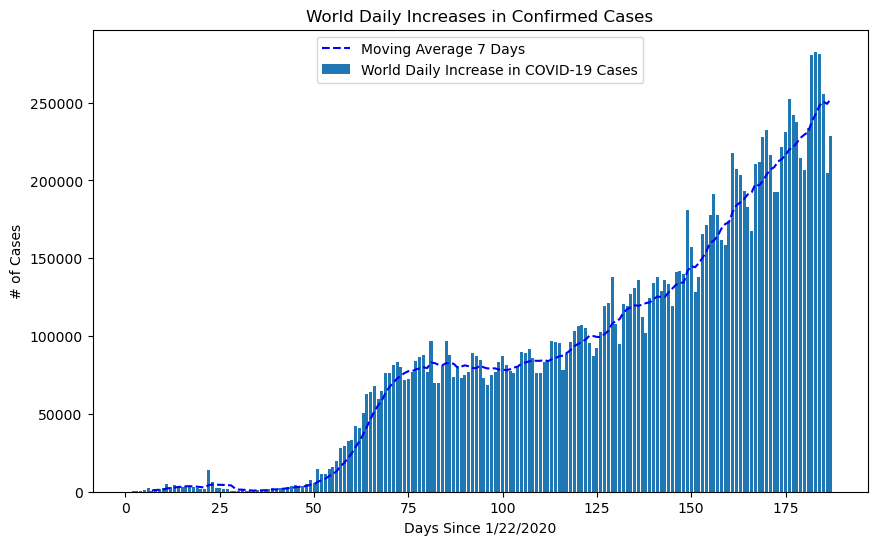

In [31]:
# Convert date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# Global aggregation
global_data = covid_df.groupby('Date')[['Confirmed']].sum().reset_index()

# Create Days column
global_data['Days'] = (global_data['Date'] - global_data['Date'].min()).dt.days

# Daily increase
global_data['Daily Increase'] = global_data['Confirmed'].diff()

# 7-day moving average
global_data['Moving Avg'] = global_data['Daily Increase'].rolling(window=7).mean()

# Plot
plt.figure(figsize=(10,6))

# Bars (actual data)
plt.bar(global_data['Days'], global_data['Daily Increase'],
        label='World Daily Increase in COVID-19 Cases')

# 🔵 DOTTED LINE (your answer)
plt.plot(global_data['Days'], global_data['Moving Avg'],
         linestyle='dashed', color='blue',
         label='Moving Average 7 Days')

plt.xlabel("Days Since 1/22/2020")
plt.ylabel("# of Cases")
plt.title("World Daily Increases in Confirmed Cases")

plt.legend()
plt.show()

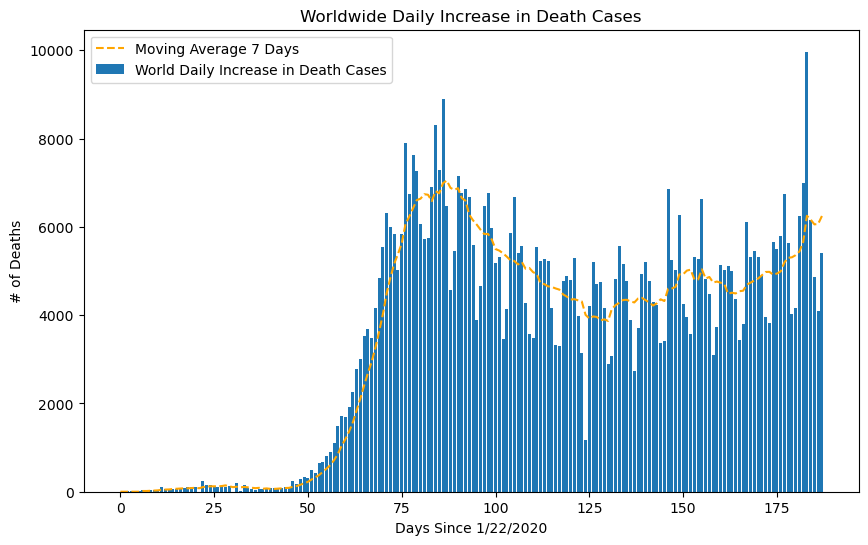

In [44]:
# Make sure Date is datetime
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# Create global aggregated data (IMPORTANT STEP)
global_data = covid_df.groupby('Date')[['Confirmed','Deaths','Recovered']].sum().reset_index()

# Create Days column
global_data['Days'] = (global_data['Date'] - global_data['Date'].min()).dt.days

# Daily deaths (fill NaN with 0)
global_data['Daily Deaths'] = global_data['Deaths'].diff().fillna(0)

# 7-day moving average (fill NaN)
global_data['Deaths MA'] = global_data['Daily Deaths'].rolling(window=7).mean().fillna(0)

# Plot
plt.figure(figsize=(10,6))

plt.bar(global_data['Days'], global_data['Daily Deaths'],
        label='World Daily Increase in Death Cases')

plt.plot(global_data['Days'], global_data['Deaths MA'],
         linestyle='dashed',
         color='Orange',
         label='Moving Average 7 Days')

plt.xlabel("Days Since 1/22/2020")
plt.ylabel("# of Deaths")
plt.title("Worldwide Daily Increase in Death Cases")

plt.legend()
plt.show()

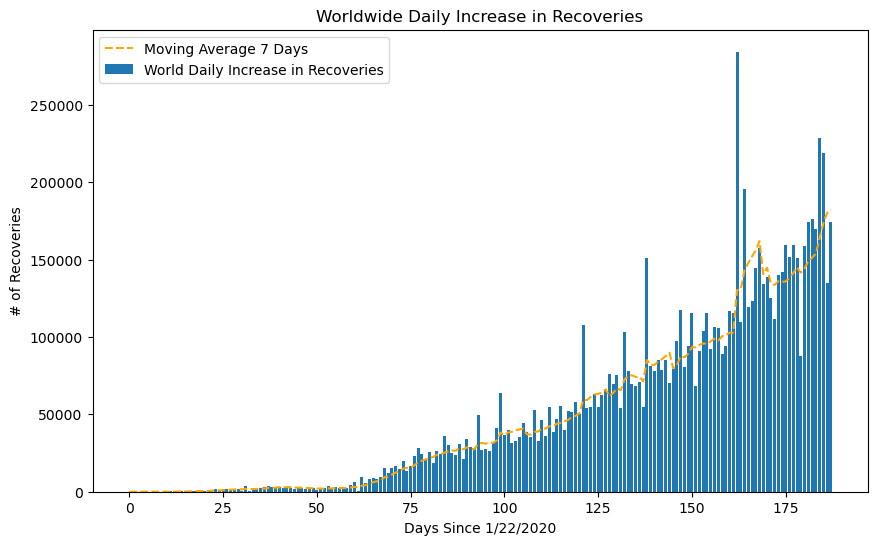

In [43]:
# Make sure Date is datetime
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# Global aggregation (important)
global_data = covid_df.groupby('Date')[['Confirmed','Deaths','Recovered']].sum().reset_index()

# Create Days column
global_data['Days'] = (global_data['Date'] - global_data['Date'].min()).dt.days

# Daily recoveries (fix NaN)
global_data['Daily Recoveries'] = global_data['Recovered'].diff().fillna(0)

# 7-day moving average (fix NaN)
global_data['Recoveries MA'] = global_data['Daily Recoveries'].rolling(window=7).mean().fillna(0)

# Plot
plt.figure(figsize=(10,6))

# Bars (actual recoveries)
plt.bar(global_data['Days'], global_data['Daily Recoveries'],
        label='World Daily Increase in Recoveries')

# 🔵 DOTTED LINE (moving average)
plt.plot(global_data['Days'], global_data['Recoveries MA'],
         linestyle='dashed',
         color='Orange',
         label='Moving Average 7 Days')

plt.xlabel("Days Since 1/22/2020")
plt.ylabel("# of Recoveries")
plt.title("Worldwide Daily Increase in Recoveries")

plt.legend()
plt.show()

In [47]:


# Load CSV (make sure filename matches extracted file)
usa_df = pd.read_csv('usa_county_wise.csv')

usa_df.head()

,UID,iso2,iso3,code3,FIPS,Admin2,Province_State,Country_Region,Lat,Long_,Combined_Key,Date,Confirmed,Deaths
0,16,AS,ASM,16,60.0,NaN,American Samoa,US,-14.271000,-170.132000,"American Samoa, US",1/22/20,0,0
1,316,GU,GUM,316,66.0,NaN,Guam,US,13.444300,144.793700,"Guam, US",1/22/20,0,0
2,580,MP,MNP,580,69.0,NaN,Northern Mariana Islands,US,15.097900,145.673900,"Northern Mariana Islands, US",1/22/20,0,0
3,63072001,PR,PRI,630,72001.0,Adjuntas,Puerto Rico,US,18.180117,-66.754367,"Adjuntas, Puerto Rico, US",1/22/20,0,0
4,63072003,PR,PRI,630,72003.0,Aguada,Puerto Rico,US,18.360255,-67.175131,"Aguada, Puerto Rico, US",1/22/20,0,0


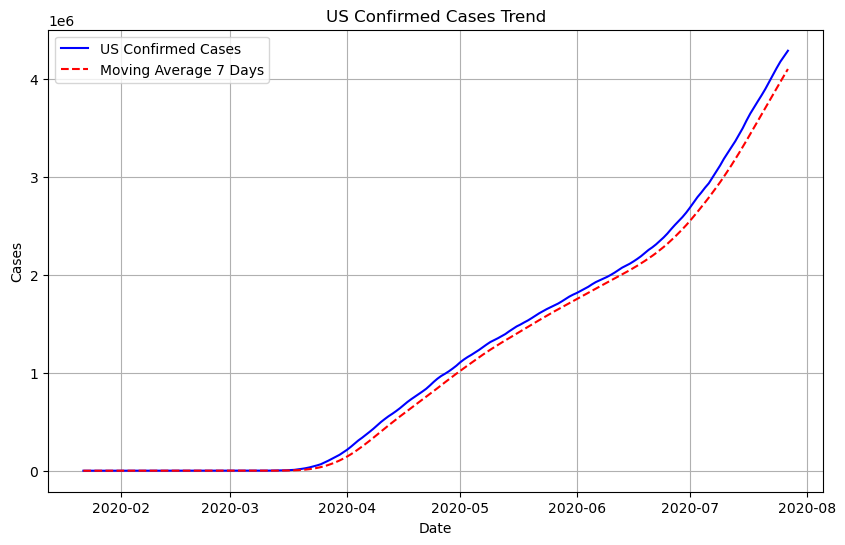

In [59]:
import pandas as pd
import matplotlib.pyplot as plt



# 2. Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 3. Create us_data (THIS WAS MISSING ❗)
us_data = covid_df[covid_df['Country/Region'] == 'US']

# 4. Group by date
us_data = us_data.groupby('Date')[['Confirmed']].sum().reset_index()

# 5. Now this will work ✅
us_data['MA7'] = us_data['Confirmed'].rolling(window=7).mean().fillna(0)

# 6. Plot
plt.figure(figsize=(10,6))

plt.plot(us_data['Date'], us_data['Confirmed'],
         color='blue', label='US Confirmed Cases')

plt.plot(us_data['Date'], us_data['MA7'],
         color='red', linestyle='dashed',
         label='Moving Average 7 Days')

plt.title("US Confirmed Cases Trend")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid(True)

plt.show()

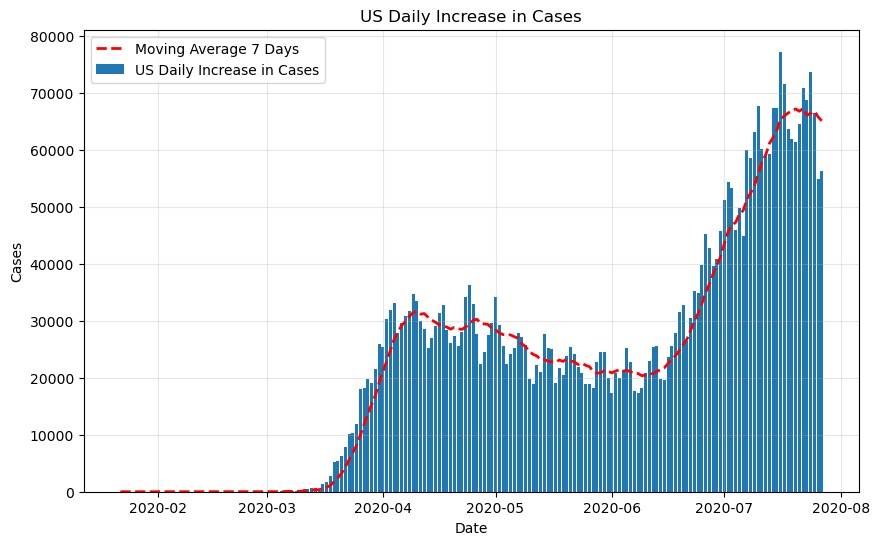

In [69]:

# 🔹 Convert Date column
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Filter USA data
us_data = covid_df[covid_df['Country/Region'] == 'US']

# 🔹 Group by Date (important)
us_data = us_data.groupby('Date')[['Confirmed']].sum().reset_index()

# 🔹 Daily increase (fix NaN)
us_data['Daily Increase'] = us_data['Confirmed'].diff().fillna(0)

# 🔹 7-day moving average
us_data['MA7'] = us_data['Daily Increase'].rolling(window=7).mean().fillna(0)

# 🔹 Plot
plt.figure(figsize=(10,6))

# Bars (daily increase)
plt.bar(us_data['Date'], us_data['Daily Increase'],
        label='US Daily Increase in Cases')

# 🔴 Dotted line (moving average)
plt.plot(us_data['Date'], us_data['MA7'],
         color='red',
         linestyle='dashed',
         linewidth=2,
         label='Moving Average 7 Days')

plt.title("US Daily Increase in Cases")
plt.xlabel("Date")
plt.ylabel("Cases")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

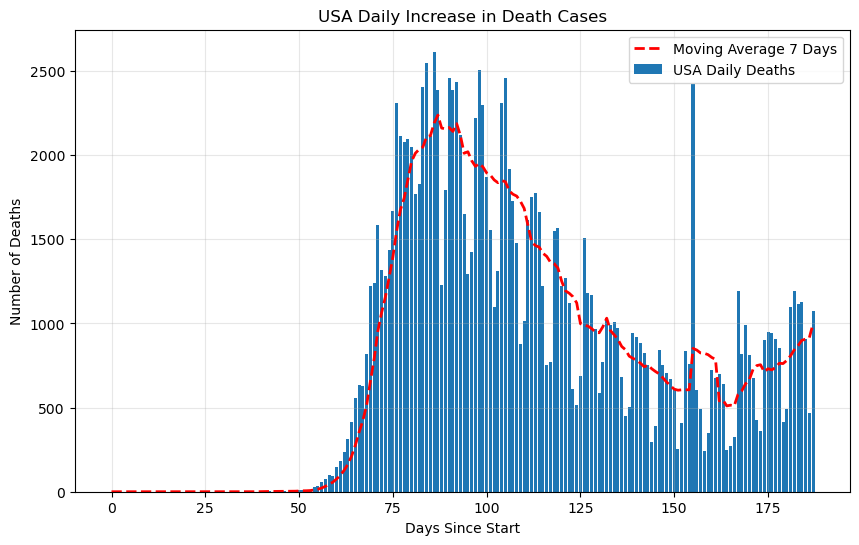

In [71]:
# 🔹 Convert Date column
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Filter USA data
usa_data = covid_df[covid_df['Country/Region'] == 'US']

# 🔹 Group by Date
usa_grouped = usa_data.groupby('Date')[['Deaths']].sum().reset_index()

# 🔹 Create Days column (for x-axis like report)
usa_grouped['Days'] = (usa_grouped['Date'] - usa_grouped['Date'].min()).dt.days

# 🔹 Daily deaths (fix NaN)
usa_grouped['Daily Deaths'] = usa_grouped['Deaths'].diff().fillna(0)

# 🔹 7-day moving average
usa_grouped['Deaths MA'] = usa_grouped['Daily Deaths'].rolling(window=7).mean().fillna(0)

# 🔹 Plot
plt.figure(figsize=(10,6))

# Bars
plt.bar(usa_grouped['Days'], usa_grouped['Daily Deaths'],
        label='USA Daily Deaths')

# 🔵 Dotted line
plt.plot(usa_grouped['Days'], usa_grouped['Deaths MA'],
         linestyle='dashed',
         color='red',
         linewidth=2,
         label='Moving Average 7 Days')

# Labels & Title
plt.xlabel("Days Since Start")
plt.ylabel("Number of Deaths")
plt.title("USA Daily Increase in Death Cases")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

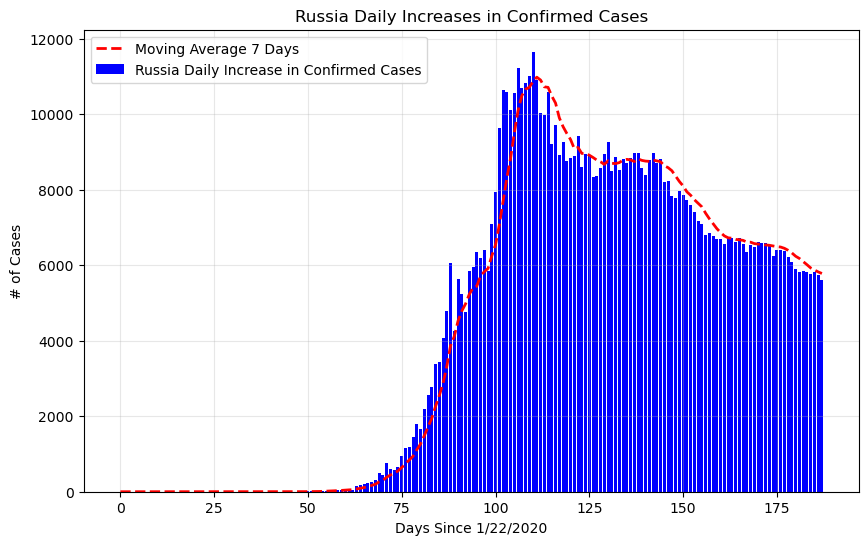

In [78]:


# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Filter Russia
russia_data = covid_df[covid_df['Country/Region'] == 'Russia']

# 🔹 Group by Date
russia_data = russia_data.groupby('Date')[['Confirmed']].sum().reset_index()

# 🔹 Create Days column (IMPORTANT for x-axis like image)
russia_data['Days'] = (russia_data['Date'] - russia_data['Date'].min()).dt.days

# 🔹 Daily increase
russia_data['Daily Increase'] = russia_data['Confirmed'].diff().fillna(0)

# 🔹 Moving average (7 days)
russia_data['MA7'] = russia_data['Daily Increase'].rolling(window=7).mean().fillna(0)

# 🔹 Plot
plt.figure(figsize=(10,6))

# Blue bars
plt.bar(russia_data['Days'], russia_data['Daily Increase'],
        color='blue',
        label='Russia Daily Increase in Confirmed Cases')

# 🔴 Red dashed line
plt.plot(russia_data['Days'], russia_data['MA7'],
         linestyle='dashed',
         color='red',
         linewidth=2,
         label='Moving Average 7 Days')

# Labels & Title (match your image)
plt.xlabel("Days Since 1/22/2020")
plt.ylabel("# of Cases")
plt.title("Russia Daily Increases in Confirmed Cases")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

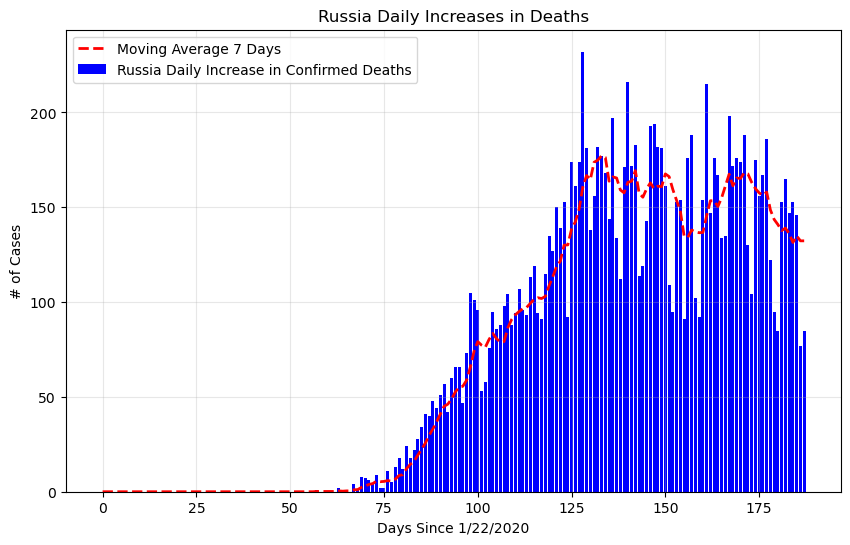

In [79]:

# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Filter Russia
russia_data = covid_df[covid_df['Country/Region'] == 'Russia']

# 🔹 Group by Date
russia_data = russia_data.groupby('Date')[['Deaths']].sum().reset_index()

# 🔹 Create Days column
russia_data['Days'] = (russia_data['Date'] - russia_data['Date'].min()).dt.days

# 🔹 Daily deaths
russia_data['Daily Deaths'] = russia_data['Deaths'].diff().fillna(0)

# 🔹 7-day moving average
russia_data['MA7'] = russia_data['Daily Deaths'].rolling(window=7).mean().fillna(0)

# 🔹 Plot
plt.figure(figsize=(10,6))

# 🔵 Blue bars
plt.bar(russia_data['Days'], russia_data['Daily Deaths'],
        color='blue',
        label='Russia Daily Increase in Confirmed Deaths')

# 🔴 Red dashed line
plt.plot(russia_data['Days'], russia_data['MA7'],
         linestyle='dashed',
         color='red',
         linewidth=2,
         label='Moving Average 7 Days')

# Labels & title (match image)
plt.xlabel("Days Since 1/22/2020")
plt.ylabel("# of Cases")
plt.title("Russia Daily Increases in Deaths")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

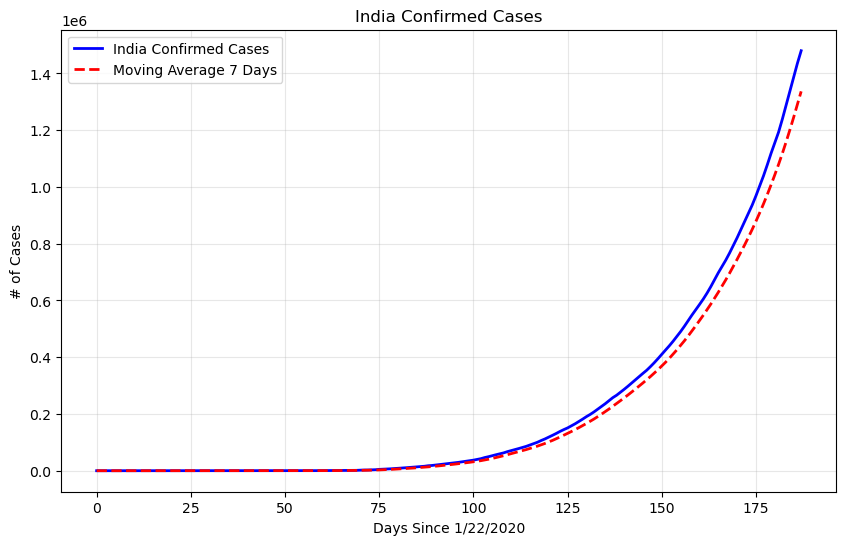

In [80]:
# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Filter India data
india_data = covid_df[covid_df['Country/Region'] == 'India']

# 🔹 Group by Date
india_data = india_data.groupby('Date')[['Confirmed']].sum().reset_index()

# 🔹 Create Days column
india_data['Days'] = (india_data['Date'] - india_data['Date'].min()).dt.days

# 🔹 7-day moving average
india_data['MA7'] = india_data['Confirmed'].rolling(window=7).mean().fillna(0)

# 🔹 Plot
plt.figure(figsize=(10,6))

# 🔵 Blue line (actual cases)
plt.plot(india_data['Days'], india_data['Confirmed'],
         color='blue',
         linewidth=2,
         label='India Confirmed Cases')

# 🔴 Red dashed line (moving average)
plt.plot(india_data['Days'], india_data['MA7'],
         color='red',
         linestyle='dashed',
         linewidth=2,
         label='Moving Average 7 Days')

# Labels & title
plt.xlabel("Days Since 1/22/2020")
plt.ylabel("# of Cases")
plt.title("India Confirmed Cases")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

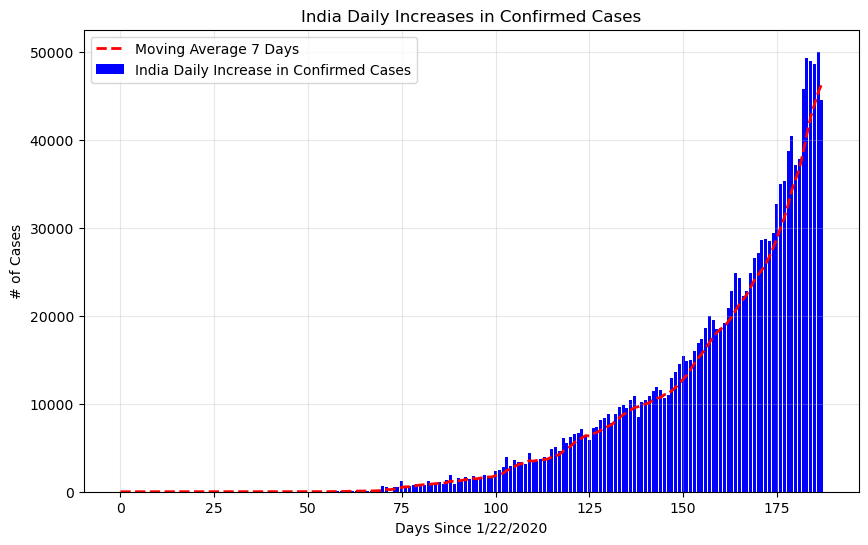

In [81]:


# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Filter India
india_data = covid_df[covid_df['Country/Region'] == 'India']

# 🔹 Group by Date
india_data = india_data.groupby('Date')[['Confirmed']].sum().reset_index()

# 🔹 Create Days column
india_data['Days'] = (india_data['Date'] - india_data['Date'].min()).dt.days

# 🔹 Daily increase
india_data['Daily Increase'] = india_data['Confirmed'].diff().fillna(0)

# 🔹 7-day moving average
india_data['MA7'] = india_data['Daily Increase'].rolling(window=7).mean().fillna(0)

# 🔹 Plot
plt.figure(figsize=(10,6))

# 🔵 Blue bars
plt.bar(india_data['Days'], india_data['Daily Increase'],
        color='blue',
        label='India Daily Increase in Confirmed Cases')

# 🔴 Red dashed line
plt.plot(india_data['Days'], india_data['MA7'],
         color='red',
         linestyle='dashed',
         linewidth=2,
         label='Moving Average 7 Days')

# Labels & title
plt.xlabel("Days Since 1/22/2020")
plt.ylabel("# of Cases")
plt.title("India Daily Increases in Confirmed Cases")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

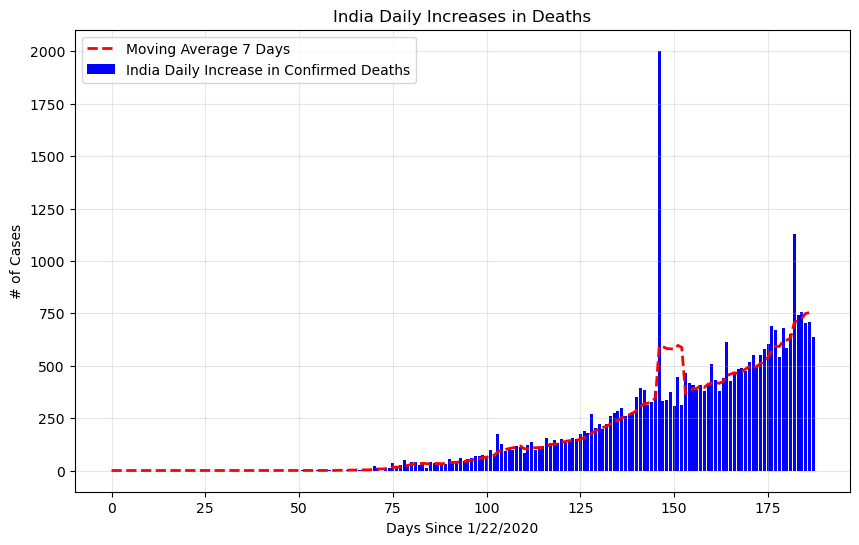

In [82]:

# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Filter India
india_data = covid_df[covid_df['Country/Region'] == 'India']

# 🔹 Group by Date
india_data = india_data.groupby('Date')[['Deaths']].sum().reset_index()

# 🔹 Create Days column
india_data['Days'] = (india_data['Date'] - india_data['Date'].min()).dt.days

# 🔹 Daily deaths
india_data['Daily Deaths'] = india_data['Deaths'].diff().fillna(0)

# 🔹 7-day moving average
india_data['MA7'] = india_data['Daily Deaths'].rolling(window=7).mean().fillna(0)

# 🔹 Plot
plt.figure(figsize=(10,6))

# 🔵 Blue bars
plt.bar(india_data['Days'], india_data['Daily Deaths'],
        color='blue',
        label='India Daily Increase in Confirmed Deaths')

# 🔴 Red dashed line
plt.plot(india_data['Days'], india_data['MA7'],
         color='red',
         linestyle='dashed',
         linewidth=2,
         label='Moving Average 7 Days')

# Labels & title
plt.xlabel("Days Since 1/22/2020")
plt.ylabel("# of Cases")
plt.title("India Daily Increases in Deaths")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

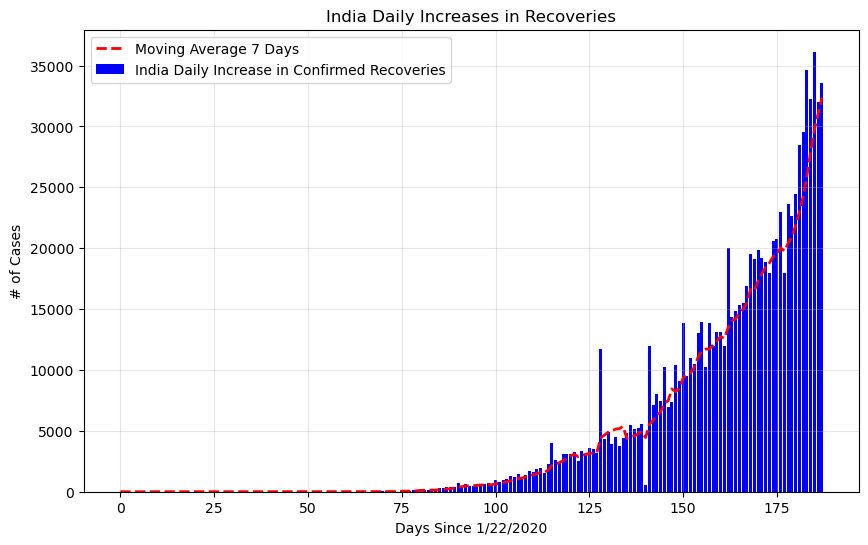

In [83]:


# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Filter India
india_data = covid_df[covid_df['Country/Region'] == 'India']

# 🔹 Group by Date
india_data = india_data.groupby('Date')[['Recovered']].sum().reset_index()

# 🔹 Create Days column
india_data['Days'] = (india_data['Date'] - india_data['Date'].min()).dt.days

# 🔹 Daily recoveries
india_data['Daily Recoveries'] = india_data['Recovered'].diff().fillna(0)

# 🔹 7-day moving average
india_data['MA7'] = india_data['Daily Recoveries'].rolling(window=7).mean().fillna(0)

# 🔹 Plot
plt.figure(figsize=(10,6))

# 🔵 Blue bars
plt.bar(india_data['Days'], india_data['Daily Recoveries'],
        color='blue',
        label='India Daily Increase in Confirmed Recoveries')

# 🔴 Red dashed line
plt.plot(india_data['Days'], india_data['MA7'],
         color='red',
         linestyle='dashed',
         linewidth=2,
         label='Moving Average 7 Days')

# Labels & Title
plt.xlabel("Days Since 1/22/2020")
plt.ylabel("# of Cases")
plt.title("India Daily Increases in Recoveries")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

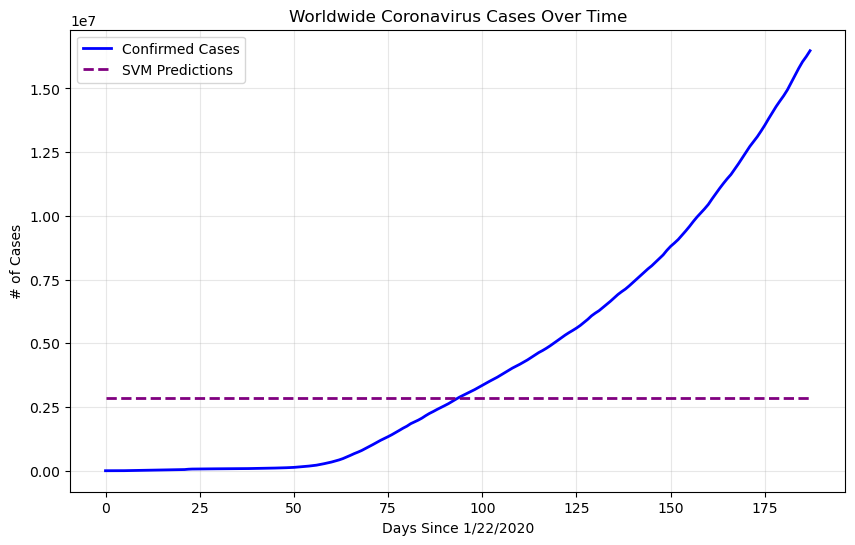

In [84]:

# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Global aggregation
world_data = covid_df.groupby('Date')[['Confirmed']].sum().reset_index()

# 🔹 Create Days column
world_data['Days'] = (world_data['Date'] - world_data['Date'].min()).dt.days

# 🔹 Features & target
X = world_data['Days'].values.reshape(-1,1)
y = world_data['Confirmed'].values

# 🔹 Train SVM model
svm_model = SVR(kernel='rbf')
svm_model.fit(X, y)

# 🔹 Predictions
svm_pred = svm_model.predict(X)

# 🔹 Plot
plt.figure(figsize=(10,6))

# 🔵 Actual data
plt.plot(world_data['Days'], y,
         color='blue',
         linewidth=2,
         label='Confirmed Cases')

# 🟣 SVM prediction (purple dashed)
plt.plot(world_data['Days'], svm_pred,
         color='purple',
         linestyle='dashed',
         linewidth=2,
         label='SVM Predictions')

# Labels & title
plt.xlabel("Days Since 1/22/2020")
plt.ylabel("# of Cases")
plt.title("Worldwide Coronavirus Cases Over Time")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [85]:


# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Global aggregation
world_data = covid_df.groupby('Date')[['Confirmed']].sum().reset_index()

# 🔹 Create Days column
world_data['Days'] = (world_data['Date'] - world_data['Date'].min()).dt.days

# 🔹 Prepare data
X = world_data['Days'].values.reshape(-1,1)
y = world_data['Confirmed'].values

# 🔹 Train SVM
svm_model = SVR(kernel='rbf')
svm_model.fit(X, y)

# 🔹 Create future days (next 10 days)
future_days = np.array(range(world_data['Days'].max()+1,
                             world_data['Days'].max()+11)).reshape(-1,1)

# 🔹 Predict future values
svm_future_pred = svm_model.predict(future_days)

# 🔹 Create future dates
last_date = world_data['Date'].max()
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1),
                             periods=10)

# 🔹 Create DataFrame (FINAL TABLE)
svm_df = pd.DataFrame({
    'Date': future_dates.strftime('%m/%d/%Y'),
    'SVM Predicted # of Confirmed Cases Worldwide': np.round(svm_future_pred)
})

# 🔹 Display table
print(svm_df)

         Date  SVM Predicted # of Confirmed Cases Worldwide
0  07/28/2020                                     2848779.0
1  07/29/2020                                     2848778.0
2  07/30/2020                                     2848777.0
3  07/31/2020                                     2848777.0
4  08/01/2020                                     2848776.0
5  08/02/2020                                     2848775.0
6  08/03/2020                                     2848774.0
7  08/04/2020                                     2848773.0
8  08/05/2020                                     2848772.0
9  08/06/2020                                     2848771.0


In [86]:


# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Global aggregation
world_data = covid_df.groupby('Date')[['Confirmed']].sum().reset_index()

# 🔹 Create Days column
world_data['Days'] = (world_data['Date'] - world_data['Date'].min()).dt.days

# 🔹 Prepare data
X = world_data['Days'].values.reshape(-1,1)
y = world_data['Confirmed'].values

# 🔹 Polynomial transformation
poly = PolynomialFeatures(degree=3)
X_poly = poly.fit_transform(X)

# 🔹 Train model
model = LinearRegression()
model.fit(X_poly, y)

# 🔹 Future days (next 10 days)
future_days = np.array(range(world_data['Days'].max()+1,
                             world_data['Days'].max()+11)).reshape(-1,1)

# 🔹 Transform future days
future_poly = poly.transform(future_days)

# 🔹 Predict
poly_pred = model.predict(future_poly)

# 🔹 Future dates
last_date = world_data['Date'].max()
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1),
                             periods=10)

# 🔹 Create final table
poly_df = pd.DataFrame({
    'Date': future_dates.strftime('%m/%d/%Y'),
    'Polynomial Predicted # of Confirmed Cases Worldwide': np.round(poly_pred)
})

# 🔹 Display
print(poly_df)

         Date  Polynomial Predicted # of Confirmed Cases Worldwide
0  07/28/2020                                         16334263.0  
1  07/29/2020                                         16562659.0  
2  07/30/2020                                         16793018.0  
3  07/31/2020                                         17025346.0  
4  08/01/2020                                         17259651.0  
5  08/02/2020                                         17495941.0  
6  08/03/2020                                         17734222.0  
7  08/04/2020                                         17974502.0  
8  08/05/2020                                         18216788.0  
9  08/06/2020                                         18461087.0  


In [87]:

# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Global aggregation
world_data = covid_df.groupby('Date')[['Confirmed']].sum().reset_index()

# 🔹 Create Days column
world_data['Days'] = (world_data['Date'] - world_data['Date'].min()).dt.days

# 🔹 Prepare data
X = world_data['Days'].values.reshape(-1,1)
y = world_data['Confirmed'].values

# 🔹 Polynomial transformation (important for Bayesian)
poly = PolynomialFeatures(degree=3)
X_poly = poly.fit_transform(X)

# 🔹 Train Bayesian Ridge model
bayesian_model = BayesianRidge()
bayesian_model.fit(X_poly, y)

# 🔹 Future days (next 10 days)
future_days = np.array(range(world_data['Days'].max()+1,
                             world_data['Days'].max()+11)).reshape(-1,1)

# 🔹 Transform future data
future_poly = poly.transform(future_days)

# 🔹 Predict
bayesian_pred = bayesian_model.predict(future_poly)

# 🔹 Create future dates
last_date = world_data['Date'].max()
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1),
                             periods=10)

# 🔹 Create final table
bayesian_df = pd.DataFrame({
    'Date': future_dates.strftime('%m/%d/%Y'),
    'Bayesian Ridge Predicted # of Confirmed Cases Worldwide': np.round(bayesian_pred)
})

# 🔹 Display
print(bayesian_df)

         Date  Bayesian Ridge Predicted # of Confirmed Cases Worldwide
0  07/28/2020                                         16445567.0      
1  07/29/2020                                         16682125.0      
2  07/30/2020                                         16920883.0      
3  07/31/2020                                         17161851.0      
4  08/01/2020                                         17405039.0      
5  08/02/2020                                         17650456.0      
6  08/03/2020                                         17898113.0      
7  08/04/2020                                         18148019.0      
8  08/05/2020                                         18400185.0      
9  08/06/2020                                         18654621.0      


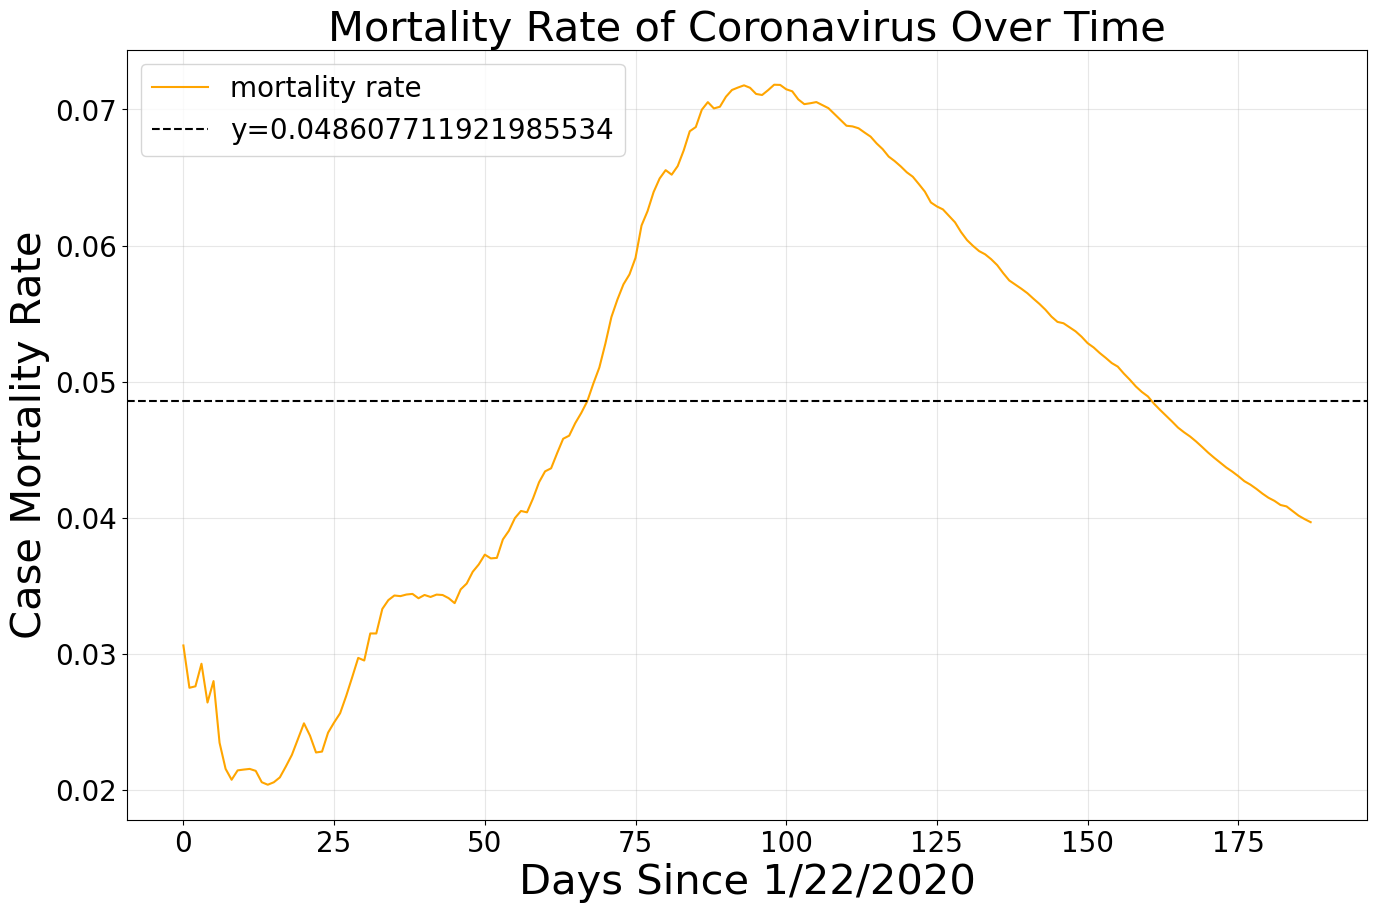

In [88]:

# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Global aggregation
world_data = covid_df.groupby('Date')[['Confirmed','Deaths']].sum().reset_index()

# 🔹 Create Days column (adjusted_dates)
world_data['Days'] = (world_data['Date'] - world_data['Date'].min()).dt.days

# 🔹 Mortality Rate = Deaths / Confirmed
world_data['mortality_rate'] = world_data['Deaths'] / world_data['Confirmed']

# 🔹 Replace NaN or inf
world_data['mortality_rate'] = world_data['mortality_rate'].replace([np.inf, -np.inf], 0).fillna(0)

# 🔹 Mean mortality rate
mean_mortality_rate = np.mean(world_data['mortality_rate'])

# 🔹 Plot
plt.figure(figsize=(16,10))

# 🟠 Mortality line
plt.plot(world_data['Days'], world_data['mortality_rate'],
         color='orange',
         label='mortality rate')

# ⚫ Mean line
plt.axhline(y=mean_mortality_rate,
            linestyle='--',
            color='black',
            label=f'y={mean_mortality_rate}')

# Labels & title
plt.title('Mortality Rate of Coronavirus Over Time', size=30)
plt.xlabel('Days Since 1/22/2020', size=30)
plt.ylabel('Case Mortality Rate', size=30)

plt.xticks(size=20)
plt.yticks(size=20)

plt.legend(prop={'size':20})
plt.grid(True, alpha=0.3)

plt.show()

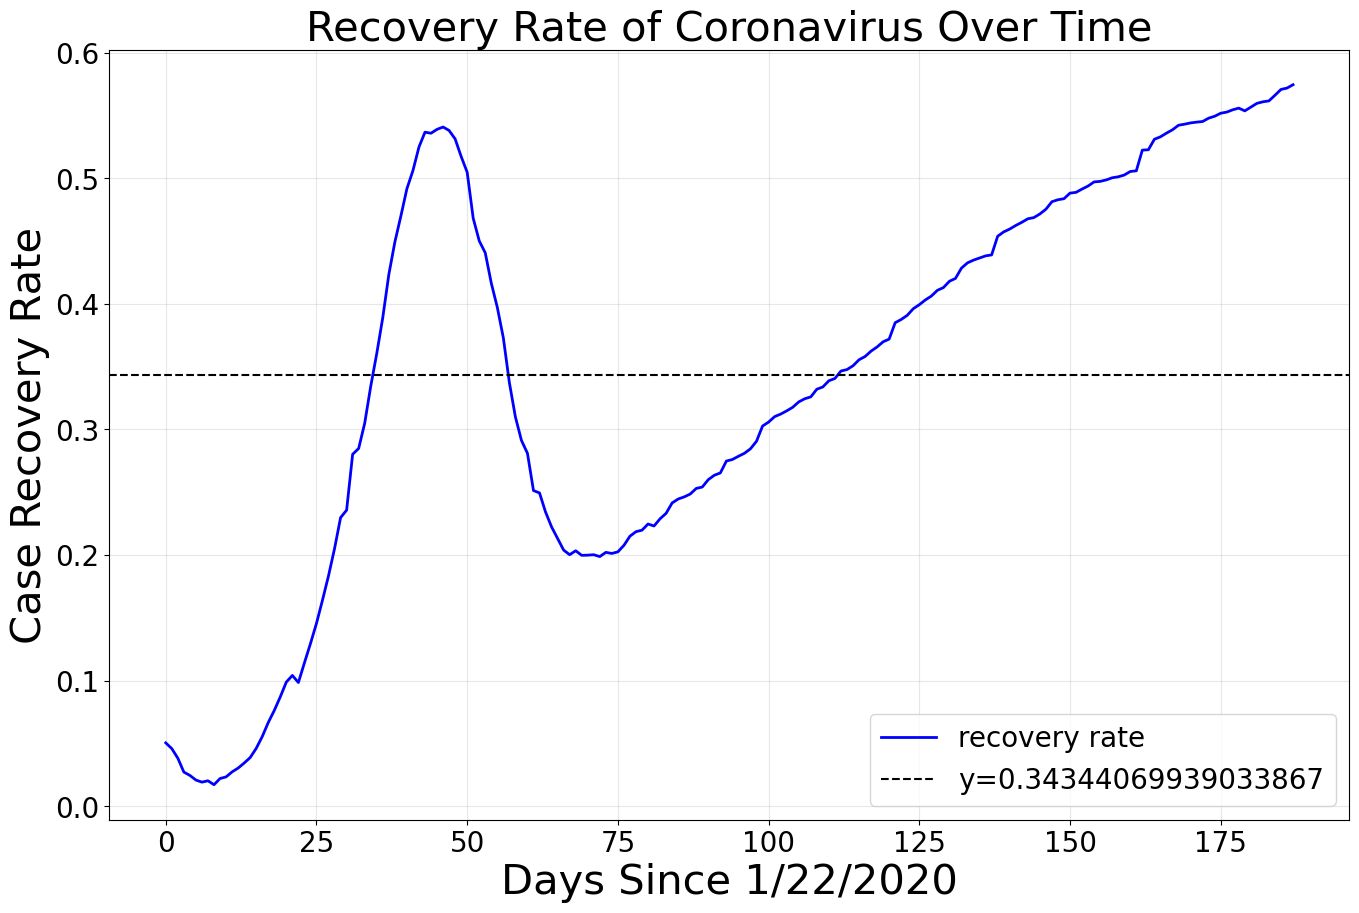

In [89]:


# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Global aggregation
world_data = covid_df.groupby('Date')[['Confirmed','Recovered']].sum().reset_index()

# 🔹 Create Days column (adjusted_dates)
world_data['Days'] = (world_data['Date'] - world_data['Date'].min()).dt.days

# 🔹 Recovery Rate = Recovered / Confirmed
world_data['recovery_rate'] = world_data['Recovered'] / world_data['Confirmed']

# 🔹 Handle divide errors
world_data['recovery_rate'] = world_data['recovery_rate'].replace([np.inf, -np.inf], 0).fillna(0)

# 🔹 Mean recovery rate
mean_recovery_rate = np.mean(world_data['recovery_rate'])

# 🔹 Plot
plt.figure(figsize=(16,10))

# 🔵 Recovery rate line
plt.plot(world_data['Days'], world_data['recovery_rate'],
         color='blue',
         linewidth=2,
         label='recovery rate')

# ⚫ Mean line
plt.axhline(y=mean_recovery_rate,
            linestyle='--',
            color='black',
            label=f'y={mean_recovery_rate}')

# Labels & title
plt.title('Recovery Rate of Coronavirus Over Time', size=30)
plt.xlabel('Days Since 1/22/2020', size=30)
plt.ylabel('Case Recovery Rate', size=30)

plt.xticks(size=20)
plt.yticks(size=20)

plt.legend(prop={'size':20})
plt.grid(True, alpha=0.3)

plt.show()

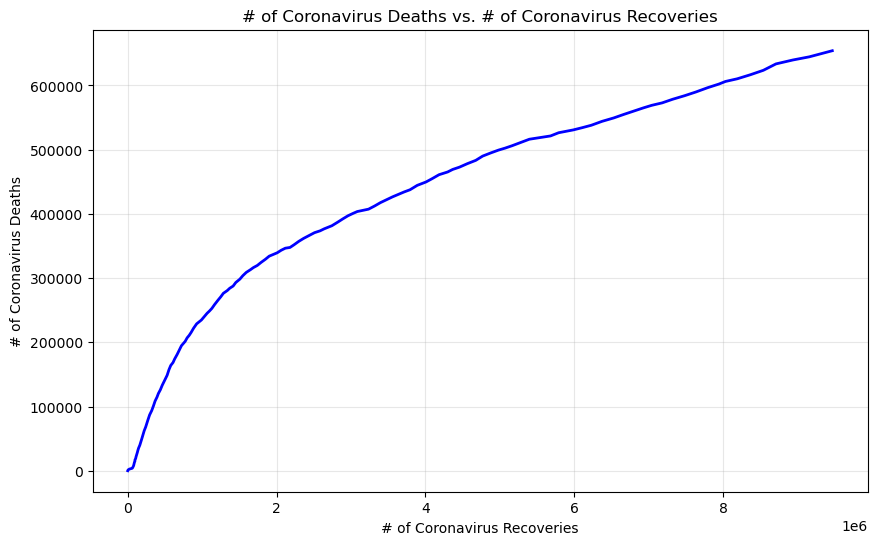

In [90]:

# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Global aggregation
world_data = covid_df.groupby('Date')[['Recovered','Deaths']].sum().reset_index()

# 🔹 Plot
plt.figure(figsize=(10,6))

plt.plot(world_data['Recovered'], world_data['Deaths'],
         color='blue',
         linewidth=2)

# Labels & title
plt.xlabel("# of Coronavirus Recoveries")
plt.ylabel("# of Coronavirus Deaths")
plt.title("# of Coronavirus Deaths vs. # of Coronavirus Recoveries")

plt.grid(True, alpha=0.3)

plt.show()

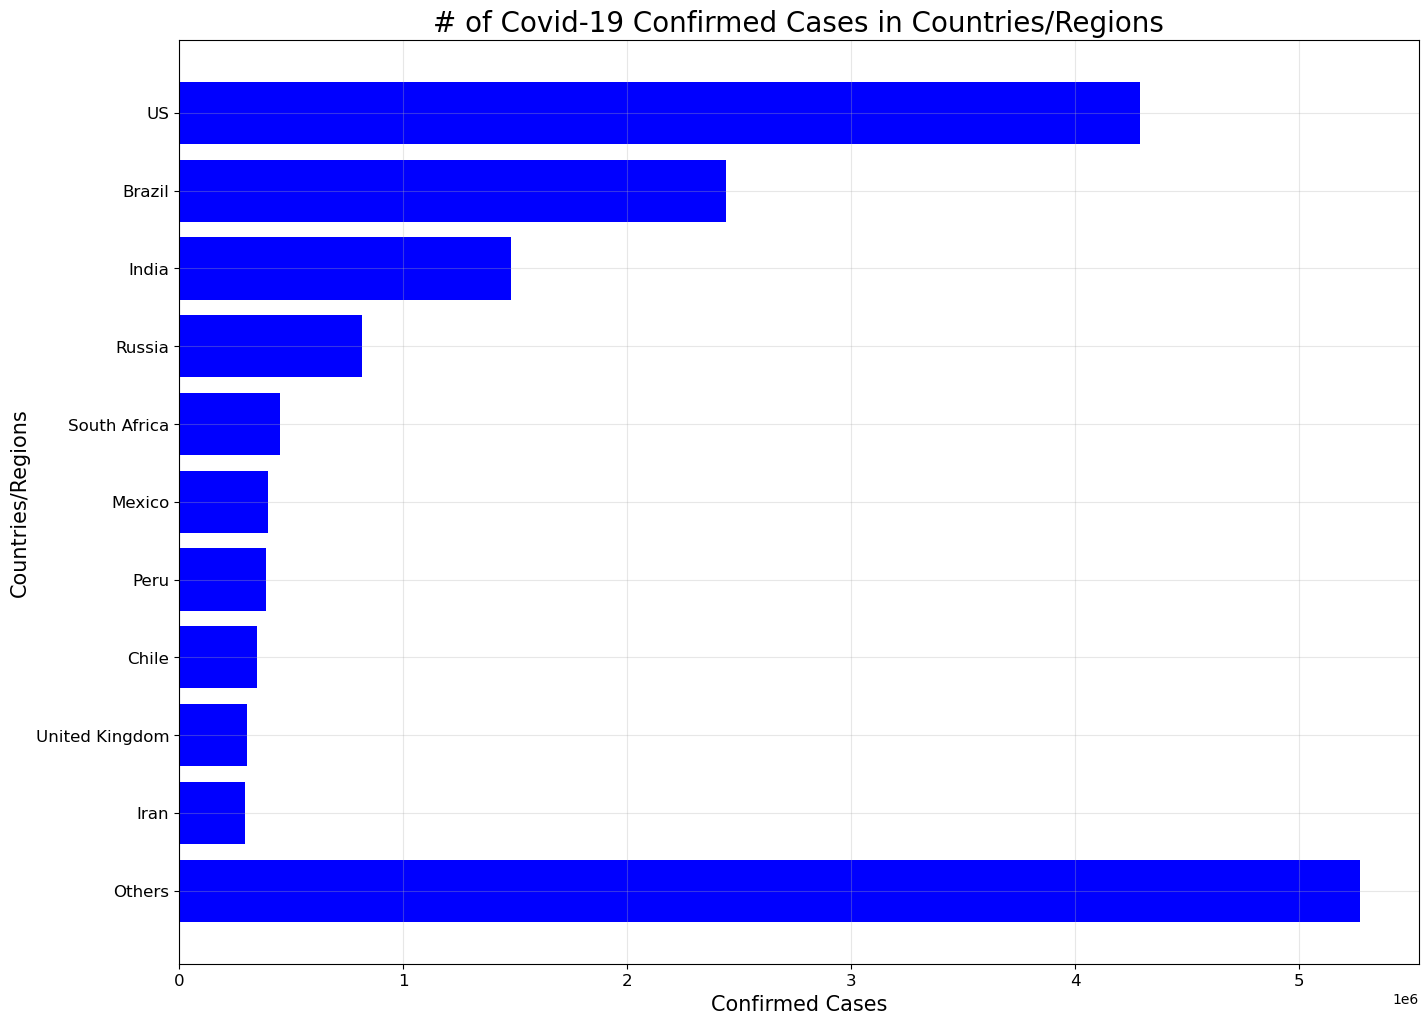

In [91]:


# 🔹 2. Convert Date column
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 3. Get latest date data
latest_date = covid_df['Date'].max()
latest_data = covid_df[covid_df['Date'] == latest_date]

# 🔹 4. Group by Country
country_data = latest_data.groupby('Country/Region')['Confirmed'].sum()

# 🔹 5. Sort descending
country_data = country_data.sort_values(ascending=False)

# 🔹 6. Top 10 countries
top_countries = country_data.head(10)

# 🔹 7. Add "Others"
others = country_data[10:].sum()

countries = list(top_countries.index) + ['Others']
cases = list(top_countries.values) + [others]

# 🔹 8. Reverse for better horizontal visualization
countries = countries[::-1]
cases = cases[::-1]

# 🔹 9. Plot function
def plot_bar_graphs(x, y, title):
    plt.figure(figsize=(16,12))
    plt.barh(x, y, color='blue')
    
    plt.title(title, size=20)
    plt.xlabel("Confirmed Cases", size=15)
    plt.ylabel("Countries/Regions", size=15)
    
    plt.xticks(size=12)
    plt.yticks(size=12)
    
    plt.grid(True, alpha=0.3)
    plt.show()

# 🔹 10. Plot graph
plot_bar_graphs(
    countries,
    cases,
    "# of Covid-19 Confirmed Cases in Countries/Regions"
)

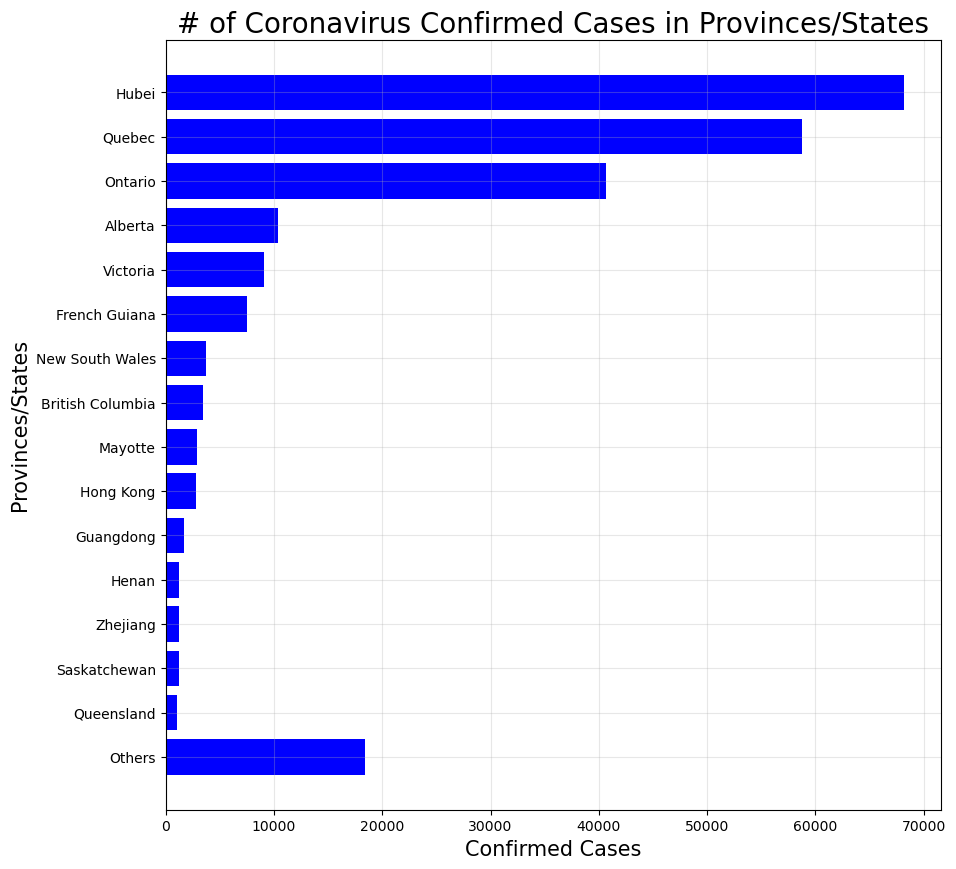

In [98]:


# 🔹 2. Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 3. Get latest data
latest_date = covid_df['Date'].max()
latest_data = covid_df[covid_df['Date'] == latest_date]

# 🔹 4. Remove empty province values
latest_data = latest_data[latest_data['Province/State'].notna()]

# 🔹 5. Group by Province/State
province_data = latest_data.groupby('Province/State')['Confirmed'].sum()

# 🔹 6. Sort descending
province_data = province_data.sort_values(ascending=False)

# 🔹 7. Top 15 provinces/states
top_provinces = province_data.head(15)

# 🔹 8. Add "Others"
others = province_data[15:].sum()

provinces = list(top_provinces.index) + ['Others']
cases = list(top_provinces.values) + [others]

# 🔹 9. Reverse for better display
provinces = provinces[::-1]
cases = cases[::-1]

# 🔹 10. Plot
plt.figure(figsize=(10,10))

plt.barh(provinces, cases, color='blue')

plt.title("# of Coronavirus Confirmed Cases in Provinces/States", size=20)
plt.xlabel("Confirmed Cases", size=15)
plt.ylabel("Provinces/States", size=15)

plt.xticks(size=10)
plt.yticks(size=10)

plt.grid(True, alpha=0.3)

plt.show()

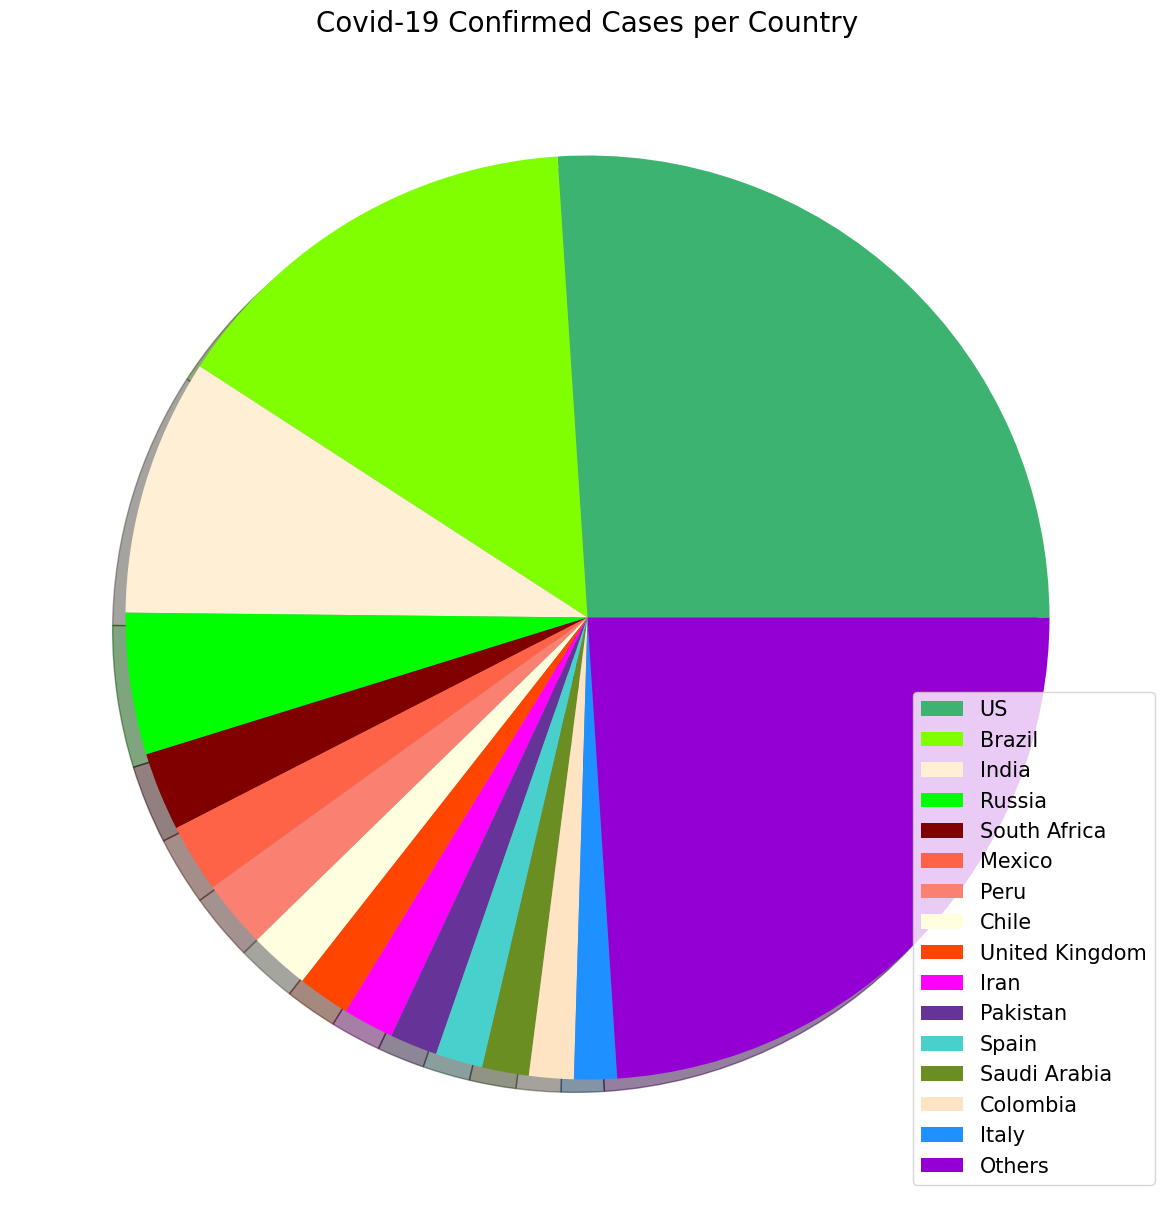

In [100]:
import pandas as pd
import matplotlib.pyplot as plt
import random
import matplotlib.colors as mcolors

# 🔹 2. Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 3. Get latest data
latest_date = covid_df['Date'].max()
latest_data = covid_df[covid_df['Date'] == latest_date]

# 🔹 4. Group by country
country_data = latest_data.groupby('Country/Region')['Confirmed'].sum()

# 🔹 5. Sort descending
country_data = country_data.sort_values(ascending=False)

# 🔹 6. Take top 15 countries
top_countries = country_data.head(15)

# 🔹 7. Add "Others"
others = country_data[15:].sum()

countries = list(top_countries.index) + ['Others']
cases = list(top_countries.values) + [others]

# 🔹 8. Generate random colors
colors = random.sample(list(mcolors.CSS4_COLORS.values()), len(countries))

# 🔹 9. Plot pie chart
plt.figure(figsize=(20,15))

plt.pie(
    cases,
    colors=colors,
    shadow=True
)

# 🔹 10. Legend (important for your style)
plt.legend(countries, loc='best', fontsize=15)

# 🔹 11. Title
plt.title('Covid-19 Confirmed Cases per Country', size=20)

plt.show()

In [119]:
import pandas as pd
import matplotlib.pyplot as plt

# 🔹 Load dataset
covid_df = pd.read_csv('covid_19_clean_complete.csv')

# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

def plot_pie_country_with_regions(country_name, title):

    # 🔹 Filter country
    df = covid_df[covid_df['Country/Region'] == country_name]

    if df.empty:
        print("❌ Country not found")
        return

    # 🔹 Latest date
    latest_date = df['Date'].max()
    df = df[df['Date'] == latest_date]

    # 🔹 Remove missing states
    df = df[df['Province/State'].notna()]

    # 🔴 FIX: if no state data → STOP
    if df.empty:
        print("❌ No state data available for this country")
        return

    # 🔹 Group
    state_data = df.groupby('Province/State')['Confirmed'].sum()

    # 🔴 Remove zero values
    state_data = state_data[state_data > 0]

    if state_data.empty:
        print("❌ All values are zero")
        return

    # 🔹 Sort
    state_data = state_data.sort_values(ascending=False)

    # 🔹 Top 5 + Others
    top_states = state_data.head(5)
    others = state_data[5:].sum()

    labels = list(top_states.index)
    values = list(top_states.values)

    if others > 0:
        labels.append('Others')
        values.append(others)

    # 🔴 FINAL SAFETY CHECK
    if len(values) == 0:
        print("❌ No data to plot")
        return

    # 🔹 Plot
    plt.figure(figsize=(10,8))

    plt.pie(
        values,
        startangle=90,
        shadow=True
    )

    plt.legend(labels, loc='upper right')
    plt.title(title)

    plt.show()


# 🔹 Run
plot_pie_country_with_regions(
    'US',
    'COVID-19 Confirmed Cases in the United States'
)

❌ No state data available for this country


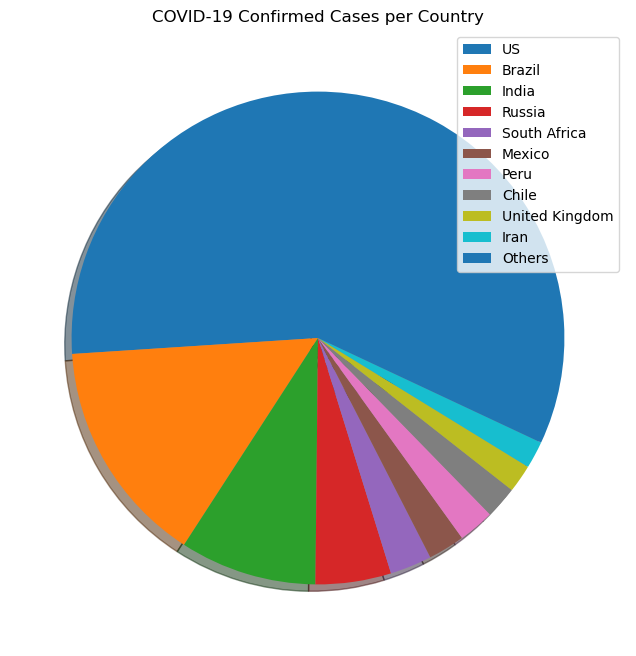

[nan]


In [122]:
import pandas as pd
import matplotlib.pyplot as plt



latest = covid_df[covid_df['Date'] == covid_df['Date'].max()]

country_data = latest.groupby('Country/Region')['Confirmed'].sum().sort_values(ascending=False)

top = country_data.head(10)
others = country_data[10:].sum()

labels = list(top.index) + ['Others']
values = list(top.values) + [others]

plt.figure(figsize=(10,8))
plt.pie(values, shadow=True, startangle=90)
plt.legend(labels, loc='best')
plt.title('COVID-19 Confirmed Cases per Country')
plt.show()
# This ONLY works if states exist
df = covid_df[covid_df['Country/Region'] == 'US']
print(df['Province/State'].unique())

Index(['UID', 'iso2', 'iso3', 'code3', 'FIPS', 'Admin2', 'Province_State',
       'Country_Region', 'Lat', 'Long_', 'Combined_Key', 'Date', 'Confirmed',
       'Deaths'],
      dtype='object')


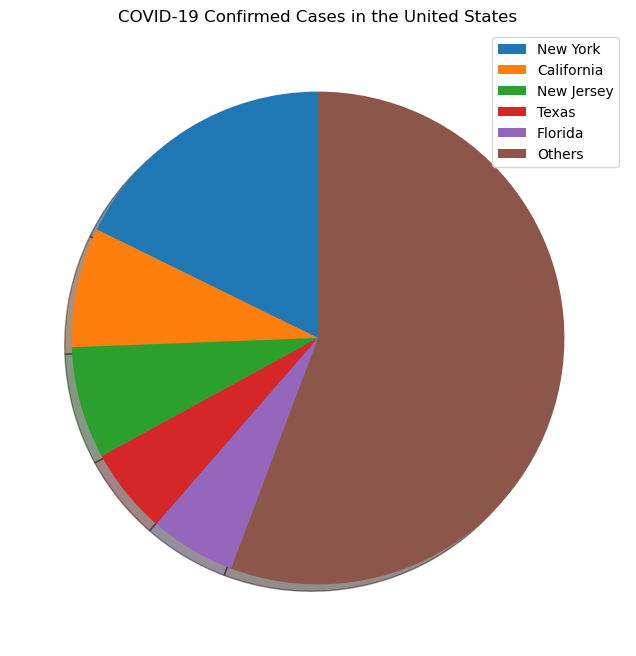

In [124]:
import pandas as pd
import matplotlib.pyplot as plt

# 🔹 Load YOUR USA dataset
# (update filename if needed)
us_df = pd.read_csv('usa_county_wise.csv')

# 🔹 Check columns once (important)
print(us_df.columns)

# 🔹 Group by state (column name may vary)
# Try one of these depending on your file:

if 'Province_State' in us_df.columns:
    state_col = 'Province_State'
elif 'Province/State' in us_df.columns:
    state_col = 'Province/State'
elif 'State' in us_df.columns:
    state_col = 'State'
else:
    raise ValueError("State column not found in dataset")

# 🔹 Get latest confirmed cases
# (if multiple dates exist → take last column)
if 'Confirmed' in us_df.columns:
    state_data = us_df.groupby(state_col)['Confirmed'].sum()
else:
    # For time-series format (dates as columns)
    latest_col = us_df.columns[-1]
    state_data = us_df.groupby(state_col)[latest_col].sum()

# 🔹 Remove zero values
state_data = state_data[state_data > 0]

# 🔹 Sort
state_data = state_data.sort_values(ascending=False)

# 🔹 Top 5 states
top_states = state_data.head(5)

# 🔹 Others
others = state_data[5:].sum()

labels = list(top_states.index) + ['Others']
values = list(top_states.values) + [others]

# 🔹 Plot
plt.figure(figsize=(10,8))

plt.pie(
    values,
    startangle=90,
    shadow=True
)

plt.legend(labels, loc='upper right')

plt.title("COVID-19 Confirmed Cases in the United States")

plt.show()

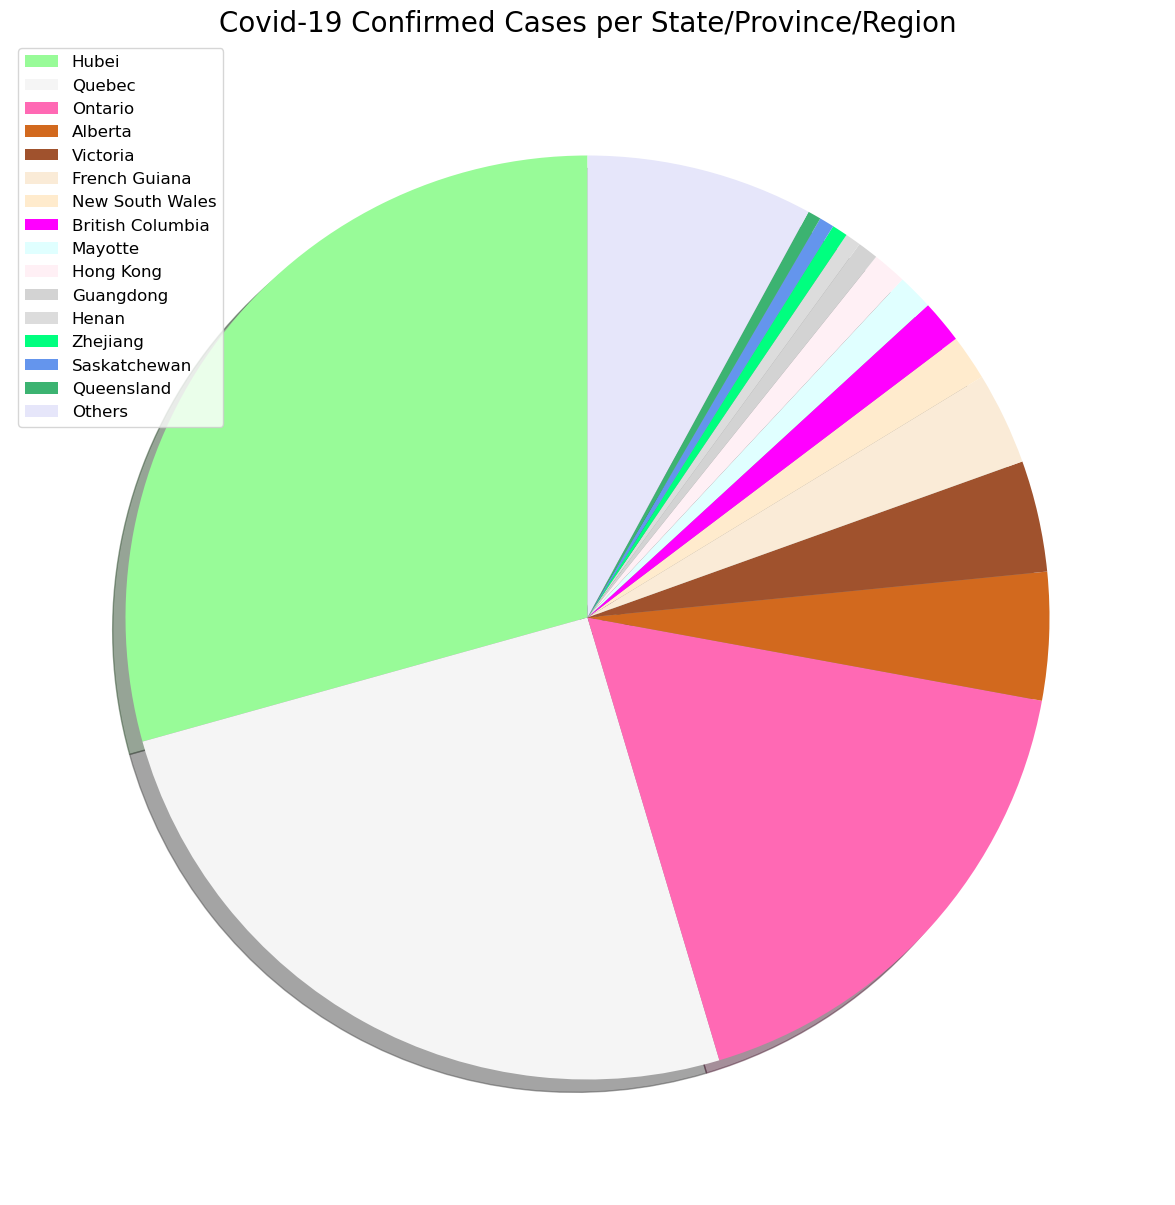

In [126]:
import pandas as pd
import matplotlib.pyplot as plt
import random
import matplotlib.colors as mcolors


# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

# 🔹 Get latest data
latest_date = covid_df['Date'].max()
latest_data = covid_df[covid_df['Date'] == latest_date]

# 🔹 Remove null states
latest_data = latest_data[latest_data['Province/State'].notna()]

# 🔹 Group by Province/State
province_data = latest_data.groupby('Province/State')['Confirmed'].sum()

# 🔹 Sort descending
province_data = province_data.sort_values(ascending=False)

# 🔹 Top 15 regions
top_regions = province_data.head(15)

# 🔹 Others
others = province_data[15:].sum()

labels = list(top_regions.index) + ['Others']
values = list(top_regions.values) + [others]

# 🔹 Generate colors
colors = random.sample(list(mcolors.CSS4_COLORS.values()), len(labels))

# 🔹 Plot
plt.figure(figsize=(20,15))

plt.pie(
    values,
    colors=colors,
    shadow=True,
    startangle=90
)

# 🔹 Legend (left side like your image)
plt.legend(labels, loc='upper left', fontsize=12)

plt.title('Covid-19 Confirmed Cases per State/Province/Region', size=20)

plt.show()

In [134]:


# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

def plot_pie_country_with_regions(country_name, title):

    df = covid_df[covid_df['Country/Region'] == country_name]

    if df.empty:
        print("❌ Country not found in dataset")
        return

    latest_date = df['Date'].max()
    df = df[df['Date'] == latest_date]

    # 🔴 Check if region data exists
    if 'Province/State' not in df.columns:
        print("❌ No Province/State column")
        return

    df = df[df['Province/State'].notna()]

    if df.empty:
        print("❌ No region/state data available for", country_name)
        return

    # 🔹 Group
    region_data = df.groupby('Province/State')['Confirmed'].sum()

    # Remove zero values
    region_data = region_data[region_data > 0]

    if region_data.empty:
        print("❌ All values are zero")
        return

    # 🔹 Sort
    region_data = region_data.sort_values(ascending=False)

    # 🔹 Top 5 + Others
    top_regions = region_data.head(5)
    others = region_data[5:].sum()

    labels = list(top_regions.index)
    values = list(top_regions.values)

    if others > 0:
        labels.append('Others')
        values.append(others)

    # 🔹 Plot
    plt.figure(figsize=(10,8))

    plt.pie(
        values,
        startangle=90,
        shadow=True
    )

    plt.legend(labels, loc='upper right')
    plt.title(title)

    plt.show()


# 🔹 Run
plot_pie_country_with_regions(
    'Italy',
    'COVID-19 Confirmed Cases in Italy'
)

❌ No region/state data available for Italy


In [133]:
print(covid_df[covid_df['Country/Region'] == 'Italy']['Province/State'].unique())
df = df[df['Province/State'].notna()]

[nan]


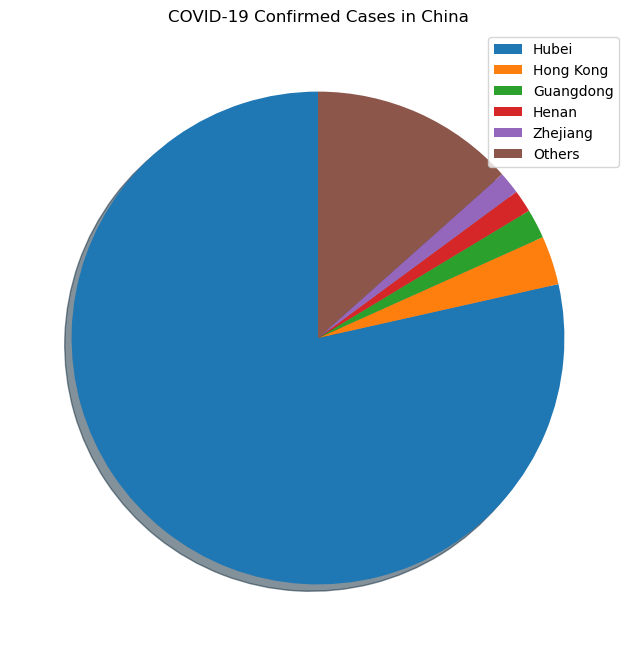

In [136]:
import pandas as pd
import matplotlib.pyplot as plt


# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

def plot_pie_country_with_regions(country_name, title):

    # 🔹 Filter country
    df = covid_df[covid_df['Country/Region'] == country_name]

    # 🔹 Latest date
    latest_date = df['Date'].max()
    df = df[df['Date'] == latest_date]

    # 🔹 Keep valid provinces
    df = df[df['Province/State'].notna()]

    # 🔹 Group by province
    province_data = df.groupby('Province/State')['Confirmed'].sum()

    # 🔹 Remove zero values
    province_data = province_data[province_data > 0]

    # 🔹 Sort descending
    province_data = province_data.sort_values(ascending=False)

    # 🔹 Top 5 + Others
    top = province_data.head(5)
    others = province_data[5:].sum()

    labels = list(top.index)
    values = list(top.values)

    if others > 0:
        labels.append('Others')
        values.append(others)

    # 🔹 Plot
    plt.figure(figsize=(10,8))

    plt.pie(
        values,
        startangle=90,
        shadow=True
    )

    plt.legend(labels, loc='upper right')
    plt.title(title)

    plt.show()


# 🔹 Run
plot_pie_country_with_regions(
    'China',
    'COVID-19 Confirmed Cases in China'
)

In [137]:


# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

def plot_pie_country_with_regions(country_name, title):

    # 🔹 Filter country
    df = covid_df[covid_df['Country/Region'] == country_name]

    if df.empty:
        print("❌ Country not found")
        return

    # 🔹 Latest date
    latest_date = df['Date'].max()
    df = df[df['Date'] == latest_date]

    # 🔹 Keep valid states
    df = df[df['Province/State'].notna()]

    if df.empty:
        print("❌ No region data available")
        return

    # 🔹 Group by state
    region_data = df.groupby('Province/State')['Confirmed'].sum()

    # 🔹 Remove zero values
    region_data = region_data[region_data > 0]

    # 🔹 Sort descending
    region_data = region_data.sort_values(ascending=False)

    # 🔹 Top 5 + Others
    top = region_data.head(5)
    others = region_data[5:].sum()

    labels = list(top.index)
    values = list(top.values)

    if others > 0:
        labels.append('Others')
        values.append(others)

    # 🔹 Colors (matching your style)
    colors = ['#e6d3a3', '#8fd3d3', '#b2b266', '#cc00cc', '#ff5733', '#d26900']

    # 🔹 Plot
    plt.figure(figsize=(10,8))

    plt.pie(
        values,
        colors=colors[:len(values)],
        startangle=90,
        shadow=True
    )

    plt.legend(labels, loc='upper right')
    plt.title(title)

    plt.show()


# 🔹 Run
plot_pie_country_with_regions(
    'Brazil',
    'COVID-19 Confirmed Cases in Brazil'
)

❌ No region data available


In [139]:

# 🔹 Convert Date
covid_df['Date'] = pd.to_datetime(covid_df['Date'])

def plot_pie_country_with_regions(country_name, title):

    # 🔹 Filter country
    df = covid_df[covid_df['Country/Region'] == country_name]

    if df.empty:
        print("❌ Country not found")
        return

    # 🔹 Latest date
    latest_date = df['Date'].max()
    df = df[df['Date'] == latest_date]

    # 🔹 Keep valid states
    df = df[df['Province/State'].notna()]

    if df.empty:
        print("❌ No state data available")
        return

    # 🔹 Group by state
    state_data = df.groupby('Province/State')['Confirmed'].sum()

    # 🔹 Remove zero values
    state_data = state_data[state_data > 0]

    # 🔹 Sort descending
    state_data = state_data.sort_values(ascending=False)

    # 🔹 Top 5 + Others
    top_states = state_data.head(5)
    others = state_data[5:].sum()

    labels = list(top_states.index)
    values = list(top_states.values)

    if others > 0:
        labels.append('Others')
        values.append(others)

    # 🔹 Colors (matching your chart)
    colors = ['#ff5733', '#d2b48c', '#800080', '#8B4513', '#4B0082', '#2ec4b6']

    # 🔹 Plot
    plt.figure(figsize=(10,8))

    plt.pie(
        values,
        colors=colors[:len(values)],
        startangle=90,
        shadow=True
    )

    plt.legend(labels, loc='upper right')
    plt.title(title)

    plt.show()


# 🔹 Run
plot_pie_country_with_regions(
    'India',
    'COVID-19 Confirmed Cases in India'
)

❌ No state data available
